In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('salary_data_cleaned.csv')
df.head()

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,...,avg_salary,Company_text,job_state,same_state,age,python_yn,R_yn,spark,aws,excel
0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973,Company - Private,...,72.0,Tecolote Research\n,NM,0,54,1,0,0,0,0
1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984,Other Organization,...,87.5,University of Maryland Medical System\n,MD,0,43,1,0,0,0,0
2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010,Company - Private,...,85.0,KnowBe4\n,FL,1,17,1,0,1,0,0
3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965,Government,...,76.5,PNNL\n,WA,1,62,1,0,0,0,0
4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,...,114.5,Affinity Solutions\n,NY,1,29,1,0,0,0,0


In [3]:
df.columns

Index(['Job Title', 'Salary Estimate', 'Job Description', 'Rating',
       'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'hourly', 'employer_provided', 'min_salary', 'max_salary', 'avg_salary',
       'Company_text', 'job_state', 'same_state', 'age', 'python_yn', 'R_yn',
       'spark', 'aws', 'excel'],
      dtype='str')

In [4]:
##job title and seniority
def title_simpifier (title):
    if 'data scientist' in title.lower():
        return 'data scientist'
    elif 'data engineer' in title.lower():
        return 'data engineer'
    elif 'analyst' in title.lower():
        return 'data analyst'
    elif 'machine learning' in title.lower():
        return 'mle'
    elif 'manager' in title.lower():
        return 'manager'
    elif 'director' in title.lower():
        return 'director'
    else: 
        return 'na'
   
def seniority(title):
    if 'sr' in title.lower() or 'senior' in title.lower() or'lead' in title.lower() or 'principal' in title.lower():
           return 'senior'
    elif 'jr' in title.lower() or 'jr.' in title.lower():
           return 'jr'
    else:
        return 'na'

In [5]:
df['job_simp'] = df['Job Title'].apply(title_simpifier)
df.job_simp.value_counts()

job_simp
data scientist    279
na                184
data engineer     119
data analyst      102
manager            22
mle                22
director           14
Name: count, dtype: int64

In [6]:
df['seniority'] = df['Job Title'].apply(seniority)
df.seniority.value_counts()

seniority
na        520
senior    220
jr          2
Name: count, dtype: int64

In [7]:
#fix state las angeles
df['job_state'] = df['job_state'].apply(lambda x: x.replace('Los Angeles', 'CA'))
df.job_state.value_counts()


job_state
CA    152
MA    103
NY     72
VA     41
IL     40
MD     35
PA     33
TX     28
WA     21
NC     21
NJ     17
FL     16
OH     14
TN     13
CO     11
DC     11
IN     10
WI     10
UT     10
MO      9
AZ      9
AL      8
KY      6
MI      6
GA      6
DE      6
CT      5
IA      5
OR      4
LA      4
NE      4
NM      3
KS      3
MN      2
ID      2
RI      1
SC      1
Name: count, dtype: int64

In [8]:
##job description length
df['desc_len'] = df['Job Description'].apply(lambda x : len(x))
df['desc_len']

0      2536
1      4783
2      3461
3      3883
4      2728
       ... 
737    6162
738    6130
739    3078
740    1642
741    3673
Name: desc_len, Length: 742, dtype: int64

In [9]:
##Competitors
df['num_comp'] = df['Competitors'].apply(lambda x: len(x.split(',')) if x != '-1' else 0)

In [10]:
##hourl wage to annual
df['min_salary'] = df.apply(lambda x : x.min_salary*2 if x.hourly ==1 else x.min_salary , axis = 1)
df['max_salary'] = df.apply(lambda x : x.max_salary*2 if x.hourly ==1 else x.max_salary , axis = 1)

In [11]:
df[df.hourly == 1 ][['min_salary', 'max_salary', 'hourly']].head(20)

,min_salary,max_salary,hourly
165,34,48,1
177,42,68,1
197,36,50,1
202,42,68,1
210,30,50,1
246,34,48,1
271,42,68,1
337,36,50,1
345,48,78,1
357,42,68,1


In [12]:
df['Company_text'] = df['Company_text'].apply(lambda x : x.replace('\n', ''))
df['Company_text']

0                          Tecolote Research
1      University of Maryland Medical System
2                                    KnowBe4
3                                       PNNL
4                         Affinity Solutions
                       ...                  
737                                      GSK
738                               Eventbrite
739           Software Engineering Institute
740                             Numeric, LLC
741             Riverside Research Institute
Name: Company_text, Length: 742, dtype: str

In [13]:
df.describe()

,Rating,Founded,hourly,employer_provided,min_salary,max_salary,avg_salary,same_state,age,python_yn,R_yn,spark,aws,excel,desc_len,num_comp
count,742.000000,742.000000,742.000000,742.000000,742.000000,742.000000,742.000000,742.000000,742.000000,742.000000,742.000000,742.000000,742.000000,742.0,742.000000,742.000000
mean,3.618868,1837.154987,0.032345,0.022911,74.719677,128.149596,100.626011,0.557951,53.119946,0.528302,0.002695,0.225067,0.237197,0.0,3869.545822,1.053908
std,0.801210,497.183763,0.177034,0.149721,30.980593,45.220324,38.855948,0.496965,54.223638,0.499535,0.051882,0.417908,0.425651,0.0,1521.495868,1.384239
min,-1.000000,-1.000000,0.000000,0.000000,15.000000,16.000000,13.500000,0.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.0,407.000000,0.000000
25%,3.300000,1939.000000,0.000000,0.000000,52.000000,96.000000,73.500000,0.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.0,2801.000000,0.000000
50%,3.700000,1988.000000,0.000000,0.000000,69.500000,124.000000,97.500000,1.000000,31.000000,1.000000,0.000000,0.000000,0.000000,0.0,3731.000000,0.000000
75%,4.000000,2007.000000,0.000000,0.000000,91.000000,155.000000,122.500000,1.000000,66.000000,1.000000,0.000000,0.000000,0.000000,0.0,4740.000000,3.000000
max,5.000000,2019.000000,1.000000,1.000000,202.000000,306.000000,254.000000,1.000000,283.000000,1.000000,1.000000,1.000000,1.000000,0.0,10051.000000,4.000000


In [15]:
df.columns


Index(['Job Title', 'Salary Estimate', 'Job Description', 'Rating',
       'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'hourly', 'employer_provided', 'min_salary', 'max_salary', 'avg_salary',
       'Company_text', 'job_state', 'same_state', 'age', 'python_yn', 'R_yn',
       'spark', 'aws', 'excel', 'job_simp', 'seniority', 'desc_len',
       'num_comp'],
      dtype='str')

<Axes: >

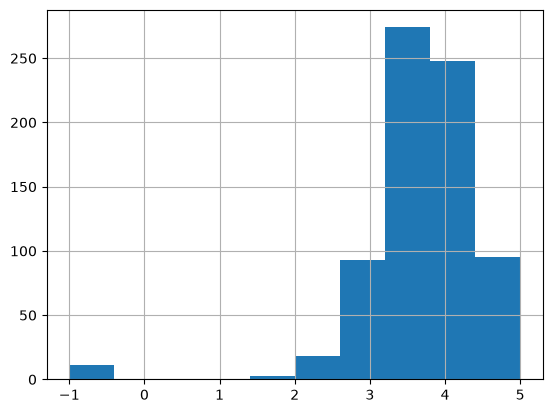

In [16]:
df.Rating.hist()

<Axes: >

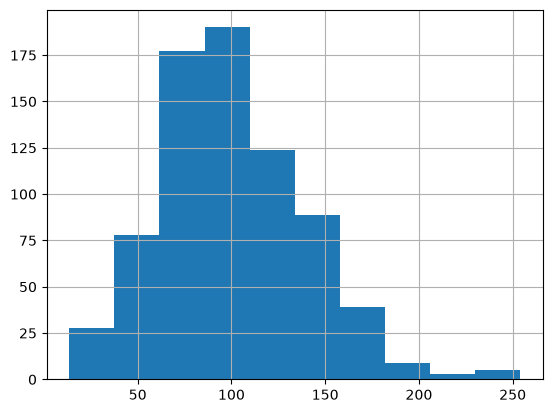

In [17]:
df.avg_salary.hist()

<Axes: >

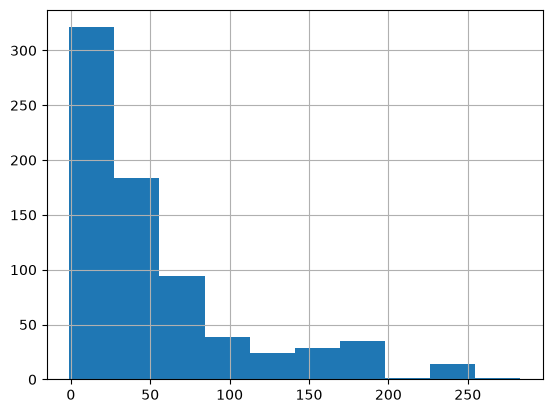

In [19]:
df.age.hist()

<Axes: >

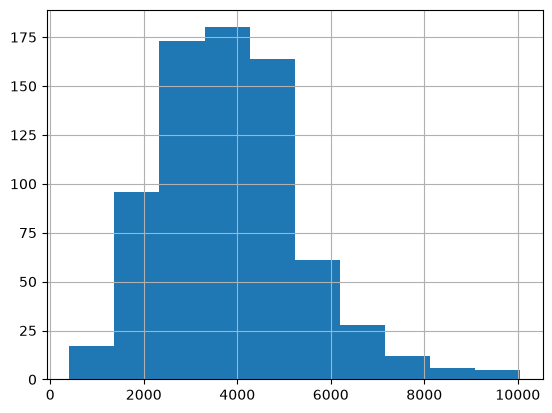

In [20]:
df.desc_len.hist()

<Axes: >

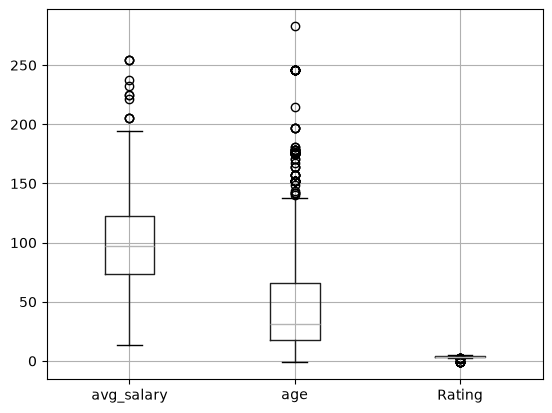

In [22]:
df.boxplot(column = ['avg_salary', 'age' , 'Rating'])

<Axes: >

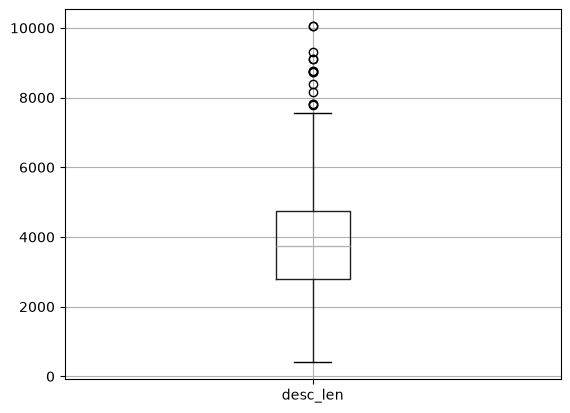

In [23]:
df.boxplot(column = 'desc_len')

In [25]:
df[['avg_salary', 'age' , 'Rating' , 'desc_len']].corr()

,avg_salary,age,Rating,desc_len
avg_salary,1.000000,0.019080,0.013492,0.078808
age,0.019080,1.000000,0.032120,0.165767
Rating,0.013492,0.032120,1.000000,-0.012281
desc_len,0.078808,0.165767,-0.012281,1.000000


<Axes: >

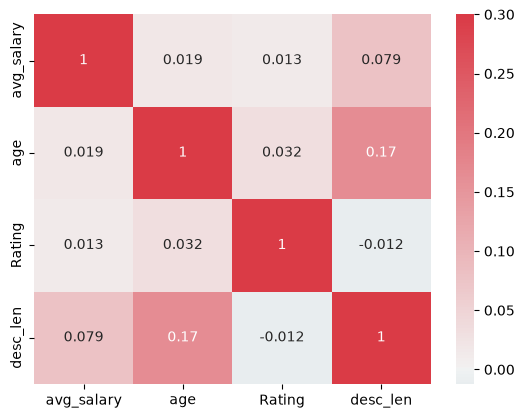

In [28]:
import seaborn as sns
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(df[['avg_salary', 'age' , 'Rating' , 'desc_len']].corr(), annot = True,vmax=.3 , center=0, cmap = cmap)

In [30]:
df.columns

Index(['Job Title', 'Salary Estimate', 'Job Description', 'Rating',
       'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'hourly', 'employer_provided', 'min_salary', 'max_salary', 'avg_salary',
       'Company_text', 'job_state', 'same_state', 'age', 'python_yn', 'R_yn',
       'spark', 'aws', 'excel', 'job_simp', 'seniority', 'desc_len',
       'num_comp'],
      dtype='str')

In [34]:
df_cat = df[['Location', 'Headquarters', 'Size', 'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Company_text', 'job_state','same_state','spark', 'aws', 'excel','job_simp','seniority']]

In [36]:

df_cat['Location'].value_counts()

Location
New York, NY         55
San Francisco, CA    49
Cambridge, MA        47
Chicago, IL          32
Boston, MA           23
                     ..
Watertown, MA         1
Cambridge, MD         1
Irvine, CA            1
Ann Arbor, MI         1
Olympia, WA           1
Name: count, Length: 200, dtype: int64

graph for Location: total= 200 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


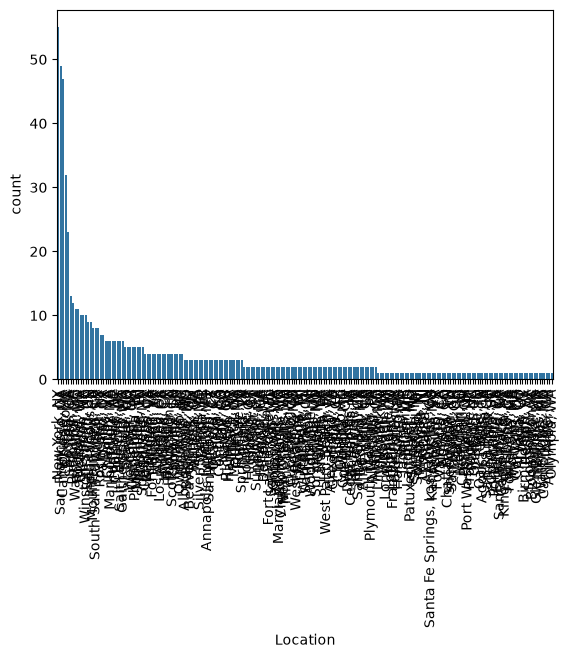

graph for Headquarters: total= 198 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


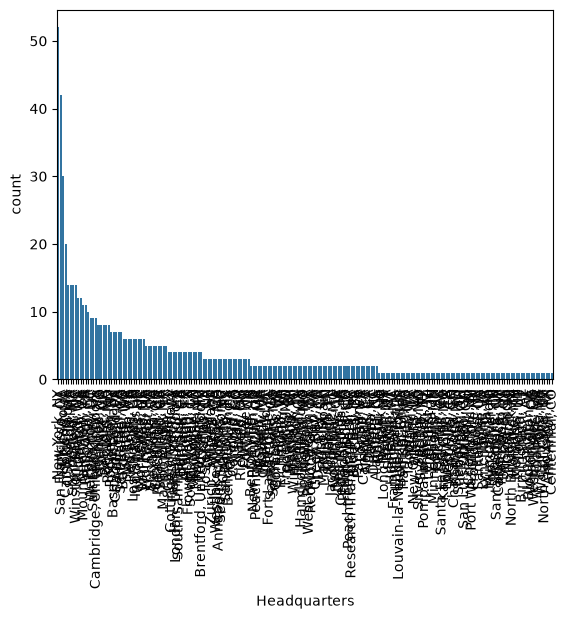

graph for Size: total= 9 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


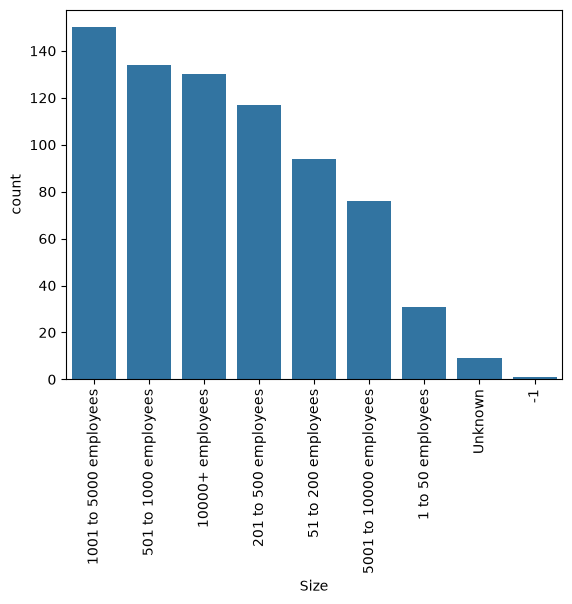

graph for Type of ownership: total= 11 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


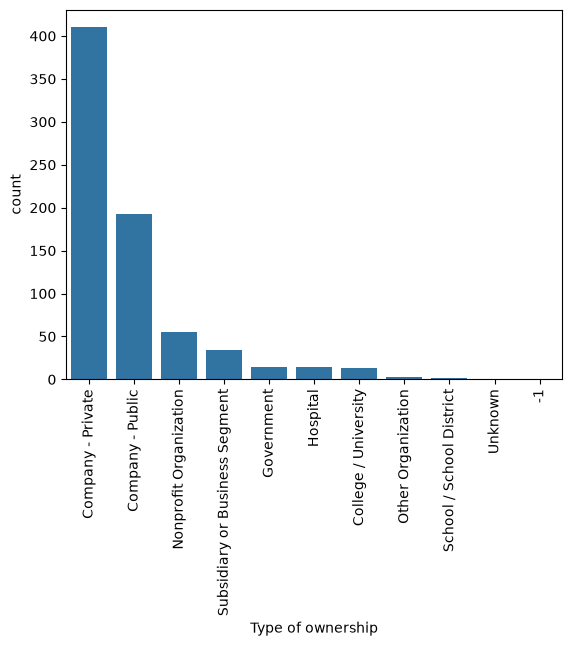

graph for Industry: total= 60 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


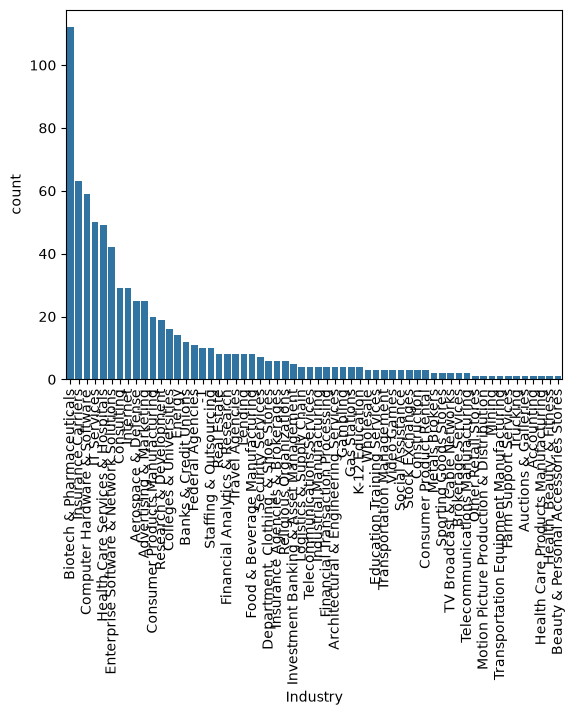

graph for Sector: total= 25 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


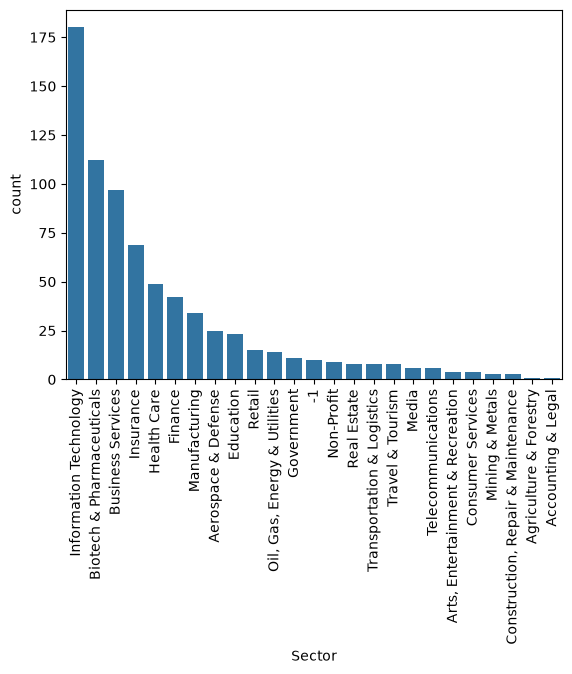

/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


graph for Revenue: total= 14 


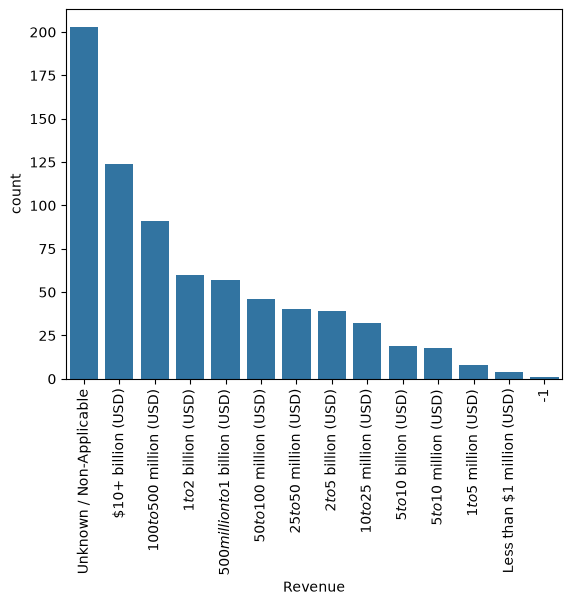

graph for Company_text: total= 343 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


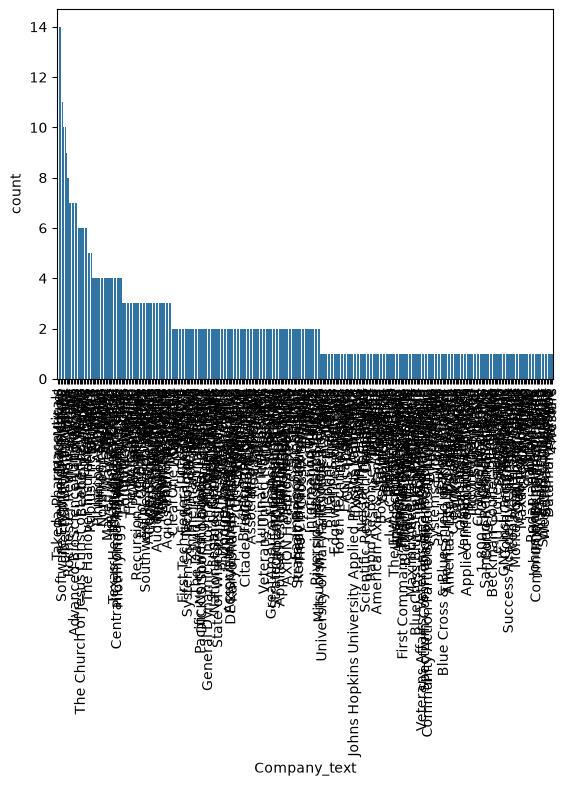

graph for job_state: total= 37 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


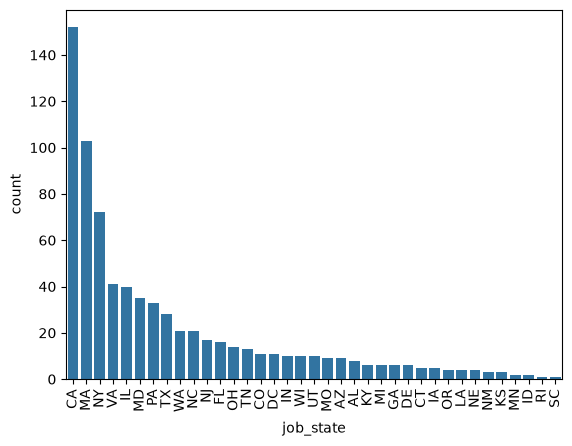

graph for same_state: total= 2 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


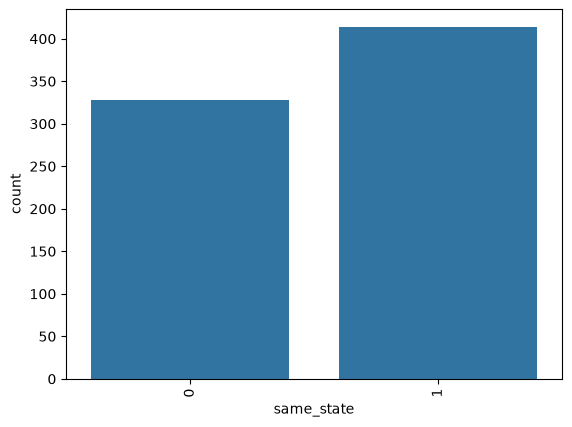

graph for spark: total= 2 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


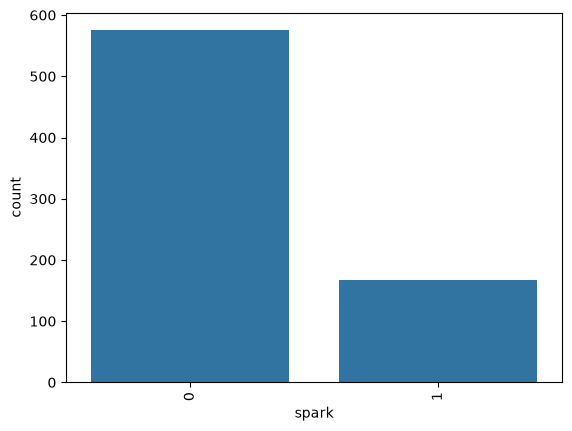

graph for aws: total= 2 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


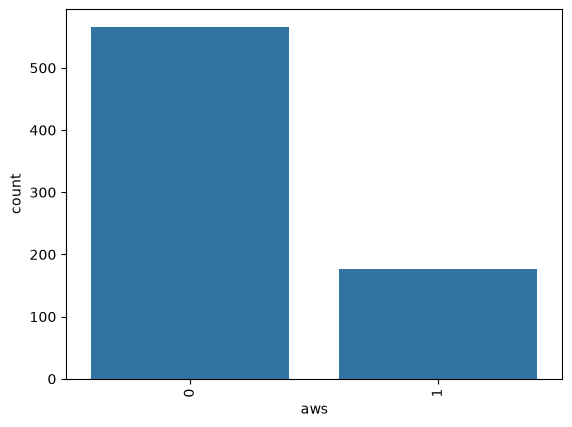

graph for excel: total= 1 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


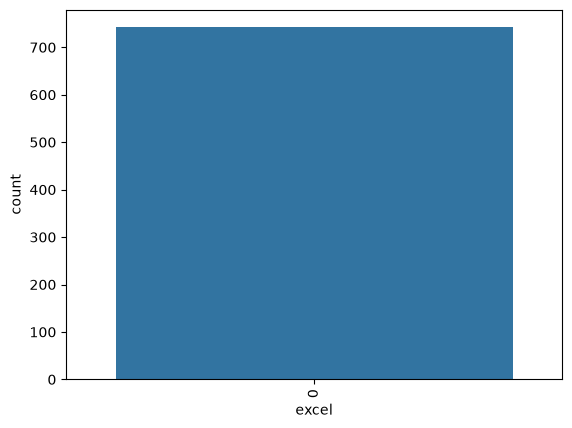

graph for job_simp: total= 7 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


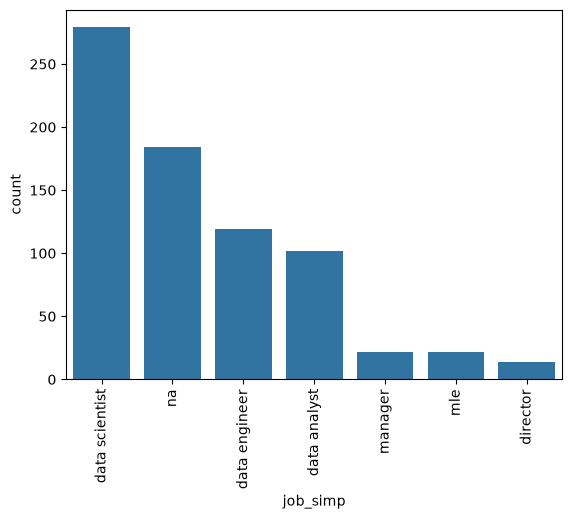

graph for seniority: total= 3 


/tmp/ipykernel_19685/897581588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


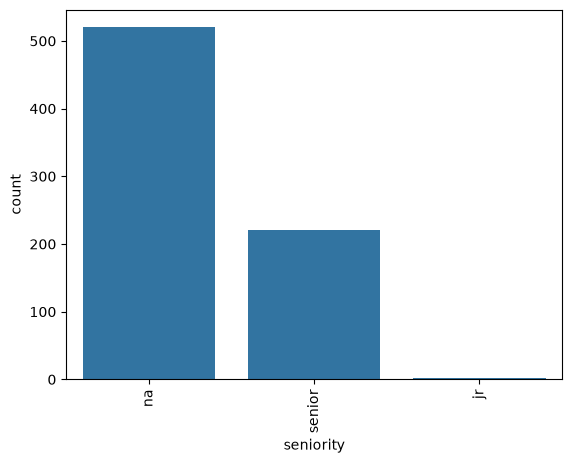

In [42]:
for i in df_cat.columns:
    cat_counts = df_cat[i].value_counts()
    print("graph for %s: total= %d " % (i, len(cat_counts)))
    chart = sns.barplot(x = cat_counts.index , y = cat_counts)
    chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)
    plt.show()

graph for Location: total= 20 


/tmp/ipykernel_19685/623602102.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


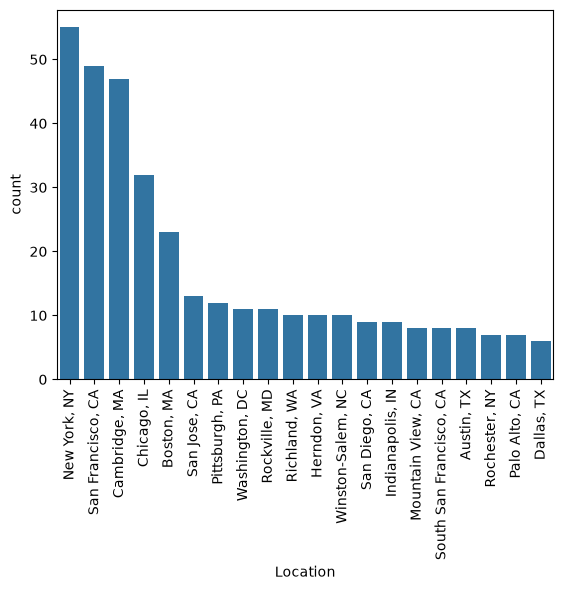

graph for Headquarters: total= 20 


/tmp/ipykernel_19685/623602102.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


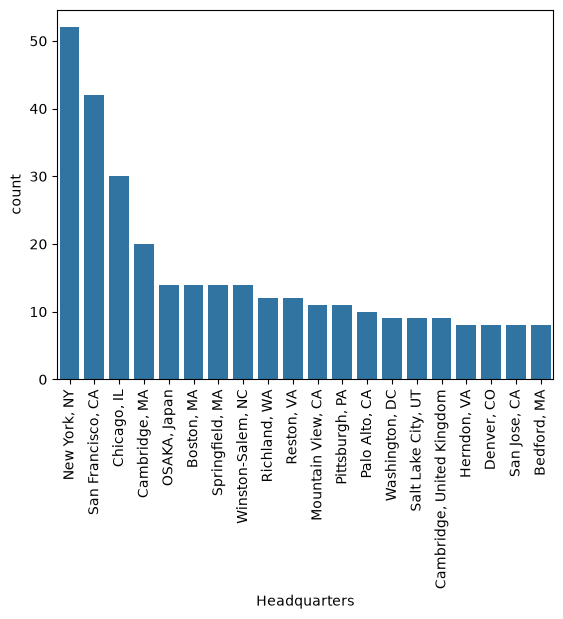

graph for Company_text: total= 20 


/tmp/ipykernel_19685/623602102.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)


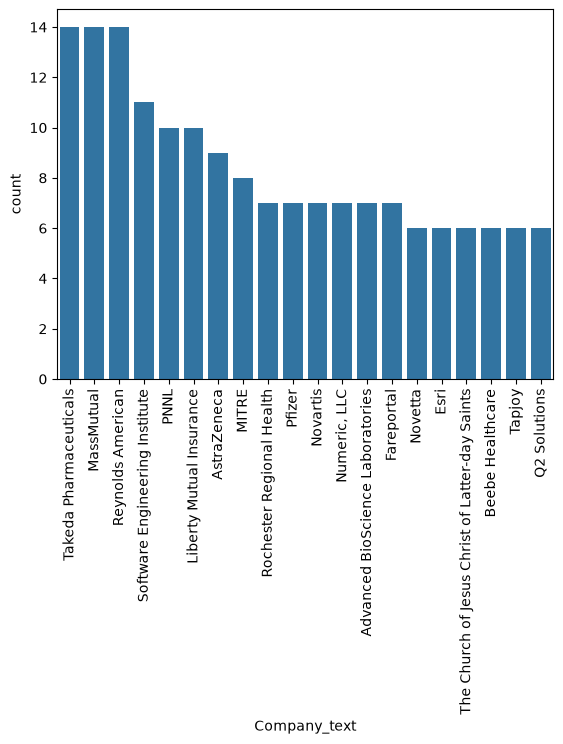

In [45]:
for i in df_cat[['Location', 'Headquarters', 'Company_text']].columns:
    cat_counts = df_cat[i].value_counts()[:20]
    print("graph for %s: total= %d " % (i, len(cat_counts)))
    chart = sns.barplot(x = cat_counts.index , y = cat_counts)
    chart.set_xticklabels(chart.get_xticklabels(), rotation = 90)
    plt.show()

In [48]:
pd.pivot_table(df , index = ['job_simp' , 'seniority'] , values = ['avg_salary'])

avg_salary
job_simp       seniority            
data analyst   jr          56.500000
               na          61.155405
               senior      79.092593
data engineer  na          96.701220
               senior     124.689189
data scientist jr         106.500000
               na         107.043011
               senior     138.956522
director       na         168.607143
manager        na          84.022727
mle            na         119.133333
               senior     142.071429
na             na          73.988189
               senior     109.061404

In [ ]:
pd.options.display.max_rows
pd.set_option('display.max_rows' , None)

pd.pivot_table(df , index = ['job_state' , 'job_simp'] , values = ['avg_salary']).sort_values('job_state' ,ascending=False)

avg_salary
job_state job_simp                  
WI        data analyst     58.833333
          data scientist  113.500000
          na               54.000000
WA        data analyst     54.500000
          data scientist   99.764706
          na               97.500000
VA        data analyst     71.583333
          data engineer    96.900000
          data scientist  108.416667
          mle              87.000000
          na               79.300000
UT        data analyst     54.750000
          data engineer   100.333333
          data scientist  140.500000
TX        data engineer   113.062500
          data scientist  100.730769
          na               41.285714
TN        data analyst     13.500000
          data engineer   100.950000
          data scientist   96.000000
SC        na               60.500000
RI        data analyst    100.000000
PA        data analyst     62.750000
          data engineer    91.500000
          data scientist  113.333333
          manager         109.666667
          mle             120.500000
          na               76.062500
OR        data engineer    73.000000
          data scientist   98.500000
OH        data analyst     53.875000
          data scientist  105.285714
          na               91.166667
NY        data analyst     65.607143
          data engineer    86.375000
          data scientist  115.250000
          mle             125.000000
          na               81.583333
NM        data scientist   74.333333
NJ        data analyst     83.583333
          data engineer   112.000000
          data scientist  106.875000
          director        161.500000
          manager         109.500000
          na               82.500000
NE        na               41.000000
NC        data engineer   104.250000
          data scientist  117.000000
          na               90.916667
MO        data analyst     61.000000
          data scientist  127.666667
          manager          40.500000
          na               72.333333
MN        data analyst     76.000000
          data engineer    95.000000
MI        data scientist  106.625000
          manager          87.500000
MD        data analyst     80.666667
          data engineer   109.000000
          data scientist  109.115385
          na               88.750000
MA        data analyst     59.125000
          data engineer   107.291667
          data scientist  113.750000
          director        117.833333
          manager          71.900000
          na              107.478261
LA        data analyst     48.000000
          data engineer    70.500000
          na               20.000000
KY        data scientist   84.000000
          na              103.500000
KS        mle              87.000000
IN        data engineer   114.500000
          data scientist   84.500000
          na               69.000000
IL        data analyst     66.500000
          data engineer    96.125000
          data scientist  117.233333
          director        221.750000
          mle             133.000000
          na               57.166667
ID        data analyst     56.250000
IA        data analyst     43.000000
          data engineer   102.833333
GA        data scientist   81.333333
          na               80.000000
FL        data analyst     47.500000
          data engineer    91.833333
          data scientist   97.357143
DE        na               27.500000
DC        data analyst     63.500000
          data engineer    85.000000
          data scientist  149.000000
CT        data scientist   84.000000
          na               62.500000
CO        data analyst     29.500000
          data engineer    99.000000
          data scientist  108.666667
          mle             100.500000
          na               31.500000
CA        data analyst     85.250000
          data engineer   129.540000
          data scientist  142.522059
          manager          80.611111
          mle             177.300000
          na               99.

In [52]:
pd.pivot_table(df[df.job_simp== 'data scientist'] , index ='job_state' , values = ['avg_salary']).sort_values('avg_salary' ,ascending=False)

,avg_salary
job_state,
DC,149.000000
CA,142.522059
UT,140.500000
MO,127.666667
IL,117.233333
NC,117.000000
NY,115.250000
MA,113.750000
WI,113.500000


In [56]:
df.columns

Index(['Job Title', 'Salary Estimate', 'Job Description', 'Rating',
       'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'hourly', 'employer_provided', 'min_salary', 'max_salary', 'avg_salary',
       'Company_text', 'job_state', 'same_state', 'age', 'python_yn', 'R_yn',
       'spark', 'aws', 'excel', 'job_simp', 'seniority', 'desc_len',
       'num_comp'],
      dtype='str')

In [ ]:
# Rating ,  Industry , Sector , Revenue , number of comp, hourly , employer_provided , python_yn, R_yn',spark, aws, excel , desc_len , type of anwership , 

In [72]:
df_pivot = df[['Rating' ,  'Industry' , 'Sector' , 'Revenue' , 'num_comp', 'hourly' , 'employer_provided' , 'python_yn', 'R_yn', 'spark', 'aws', 'excel' , 'desc_len' , 'Type of ownership','avg_salary' ]]

In [74]:
df_pivot.cumsum()

,Rating,Industry,Sector,Revenue,num_comp,hourly,employer_provided,python_yn,R_yn,spark,aws,excel,desc_len,Type of ownership,avg_salary
0,3.8,Aerospace & Defense,Aerospace & Defense,$50 to $100 million (USD),0,0,0,1,0,0,0,0,2536,Company - Private,72.0
1,7.2,Aerospace & DefenseHealth Care Services & Hosp...,Aerospace & DefenseHealth Care,$50 to $100 million (USD)$2 to $5 billion (USD),0,0,0,2,0,0,0,0,7319,Company - PrivateOther Organization,159.5
2,12.0,Aerospace & DefenseHealth Care Services & Hosp...,Aerospace & DefenseHealth CareBusiness Services,$50 to $100 million (USD)$2 to $5 billion (USD...,0,0,0,3,0,1,0,0,10780,Company - PrivateOther OrganizationCompany - P...,244.5
3,15.8,Aerospace & DefenseHealth Care Services & Hosp...,Aerospace & DefenseHealth CareBusiness Service...,$50 to $100 million (USD)$2 to $5 billion (USD...,3,0,0,4,0,1,0,0,14663,Company - PrivateOther OrganizationCompany - P...,321.0
4,18.7,Aerospace & DefenseHealth Care Services & Hosp...,Aerospace & DefenseHealth CareBusiness Service...,$50 to $100 million (USD)$2 to $5 billion (USD...,6,0,0,5,0,1,0,0,17391,Company - PrivateOther OrganizationCompany - P...,435.5
5,22.1,Aerospace & DefenseHealth Care Services & Hosp...,Aerospace & DefenseHealth CareBusiness Service...,$50 to $100 million (USD)$2 to $5 billion (USD...,9,0,0,6,0,1,1,0,21138,Company - PrivateOther OrganizationCompany - P...,530.5
6,26.2,Aerospace & DefenseHealth Care Services & Hosp...,Aerospace & DefenseHealth CareBusiness Service...,$50 to $100 million (USD)$2 to $5 billion (USD...,9,0,0,6,0,1,1,0,22924,Company - PrivateOther OrganizationCompany - P...,604.0
7,30.0,Aerospace & DefenseHealth Care Services & Hosp...,Aerospace & DefenseHealth CareBusiness Service...,$50 to $100 million (USD)$2 to $5 billion (USD...,9,0,0,7,0,2,2,0,26728,Company - PrivateOther OrganizationCompany - P...,718.0
8,33.3,Aerospace & DefenseHealth Care Services & Hosp...,Aerospace & DefenseHealth CareBusiness Service...,$50 to $100 million (USD)$2 to $5 billion (USD...,9,0,0,7,0,2,2,0,28266,Company - PrivateOther OrganizationCompany - P...,779.0
9,37.9,Aerospace & DefenseHealth Care Services & Hosp...,Aerospace & DefenseHealth CareBusiness Service...,$50 to $100 million (USD)$2 to $5 billion (USD...,11,0,0,8,0,3,2,0,32840,Company - PrivateOther OrganizationCompany - P...,919.0


In [ ]:
for i in df_pivot.columns:
    print(i)
    print(pd.pivot_table(df_pivot ,index = i, values = 'avg_salary').sort_values('avg_salary' ,ascending=False))

Rating
        avg_salary
Rating            
-1.0    136.181818
 1.9     87.500000
 2.1     95.900000
 2.2     97.750000
 2.3     81.500000
 2.4     60.214286
 2.5    120.000000
 2.6    109.083333
 2.7     83.250000
 2.8     83.928571
 2.9     81.138889
 3.0     85.588235
 3.1     86.580000
 3.2    105.500000
 3.3    101.858974
 3.4     93.011364
 3.5    104.897959
 3.6     85.467391
 3.7    104.131148
 3.8     96.811475
 3.9    113.071429
 4.0    105.340426
 4.1    116.368421
 4.2    100.442308
 4.3    102.468750
 4.4    108.606061
 4.5    117.714286
 4.6     97.250000
 4.7    103.983871
 4.8     80.277778
 5.0    134.700000
Industry
                                          avg_salary
Industry                                            
-1                                        114.650000
Accounting                                113.500000
Advertising & Marketing                   104.300000
Aerospace & Defense                        99.060000
Architectural & Engineering Services   

ValueError: Grouper for 'avg_salary' not 1-dimensional

In [89]:
pd.pivot_table(df_pivot, index = 'Revenue' , columns='python_yn' , values='avg_salary' , aggfunc='count')

python_yn,0,1
Revenue,,
$1 to $2 billion (USD),16.0,44.0
$1 to $5 million (USD),1.0,7.0
$10 to $25 million (USD),16.0,16.0
$10+ billion (USD),66.0,58.0
$100 to $500 million (USD),47.0,44.0
$2 to $5 billion (USD),17.0,22.0
$25 to $50 million (USD),24.0,16.0
$5 to $10 billion (USD),9.0,10.0
$5 to $10 million (USD),9.0,9.0


In [91]:
df.to_csv('eda_data.csv')